* RMSE is a metric that measures how far off a model's prediction is from actual data on a validation dataset. Lower is good. 

- For example: model A trained neural networks with 100+ parameter's rmse is 10.0. Model B trianed with linear regression with 5 parameter's rmse is 10.05. 

- Conclusion: Model A is better but Model B is within 1% of model A. Just because the rmse is is so close, thus, the winner is the model with the lowest validation RMSE. If another model is within 1% and simpler (lower degree), I pick the simpler one which is Model B, much faster to train.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

In [3]:
df = pd.read_csv(url)
df = df[df["median_house_value"] < 500001].copy()
print(df.shape)

(19675, 10)


In [4]:
d = pd.get_dummies(df, columns=["ocean_proximity"], dtype=int)
feat = ["median_income", "housing_median_age", "latitude", "longitude"] + \
       [c for c in d.columns if c.startswith("ocean_proximity")]
X, y = d[feat], d["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42
)

print(X.shape, X_tr.shape, X_val.shape, X_test.shape)
print(feat)

(19675, 9) (11805, 9) (3935, 9) (3935, 9)
['median_income', 'housing_median_age', 'latitude', 'longitude', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


In [5]:
def rmse(a, b):
    return mean_squared_error(a, b) ** 0.5

def make_model(degree=1, alpha=None):
    steps = []
    if degree > 1:
        steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))
    steps.append(("sc", StandardScaler()))
    steps.append(("model", LinearRegression() if alpha is None else Ridge(alpha=alpha)))
    return Pipeline(steps)

def evaluate(model, Xa, ya):
    model.fit(Xa, ya)
    p_tr = model.predict(Xa)
    p_val = model.predict(X_val)
    return dict(train_rmse=rmse(ya, p_tr), val_rmse=rmse(y_val, p_val),
                train_r2=r2_score(ya, p_tr), val_r2=r2_score(y_val, p_val))

def take(n, seed=0):
    Xs = X_tr.sample(n=n, random_state=seed)
    return Xs, y_tr.loc[Xs.index]

base = DummyRegressor().fit(X_tr, y_tr)
print("baseline: val RMSE", round(rmse(y_val, base.predict(X_val))),
      "val R2", round(r2_score(y_val, base.predict(X_val)), 4))
lin = evaluate(make_model(1), X_tr, y_tr)
print("plain linear:", {k: round(v, 4) for k, v in lin.items()})

baseline: val RMSE 98548 val R2 -0.0009
plain linear: {'train_rmse': 63105.4994, 'val_rmse': 64180.322, 'train_r2': 0.5741, 'val_r2': 0.5755}


- We must split before compare models because to ensure data leakage and evaluate on unseen data. We keep X_val separate from X_test because we use X_val to fine tune with parameters to choose the best model while we keep X_test till the very end.
- Baseline (R2 = -0.0009) fails to explain any variance of the target variable. Plain Linear (R2 = 0.5755): This means the plain linear model successfully explains 57.55% of the variance in the data's prices using the provided features.
- median_income is matters most for price and i would check its correlation (0.643) with median_house_value.

In [6]:
Xs, ys = take(200)
rows = []
for deg in [1, 2, 3, 4, 5]:
    r = evaluate(make_model(deg), Xs, ys)
    r["degree"] = deg
    r["n_features"] = PolynomialFeatures(degree=deg, include_bias=False).fit(Xs).n_output_features_
    rows.append(r)
exp1 = pd.DataFrame(rows).set_index("degree")
print(exp1.round(3).to_string())

        train_rmse     val_rmse  train_r2   val_r2  n_features
degree                                                        
1        60484.845    66309.181     0.656    0.547           9
2        55890.314    67613.256     0.706    0.529          54
3        47957.860   104068.585     0.784   -0.116         219
4        34068.701  1402921.641     0.891 -201.837         714
5        31085.471  2900048.006     0.909 -865.743        2001


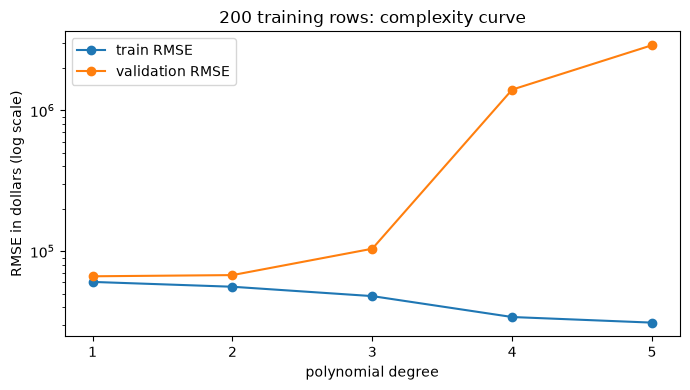

In [7]:
plt.figure(figsize=(7,4))
plt.plot(exp1.index, exp1["train_rmse"], marker="o", label="train RMSE")
plt.plot(exp1.index, exp1["val_rmse"], marker="o", label="validation RMSE")
plt.yscale("log")
plt.xticks(exp1.index)
plt.xlabel("polynomial degree")
plt.ylabel("RMSE in dollars (log scale)")
plt.title("200 training rows: complexity curve")
plt.legend()
plt.tight_layout()
plt.show()

- On degree 4 in train RMSE went backwards from degree=1(60484.845) -> degree=5(31085.471) while validation rmse increase from degree=1(66309.181) -> degree=5(2900048.006) because when you give more flexibility the training might looks better but the validation gets worse. The lower the validation rmse the better the model. Degree 5 looks better on training data. 1 is the one actually better and the name of the problem is overfitting.
- because it memorised the training data and noise leads to perform better on training r2 while get negative (-0.116) on validation r2. Degree 3 has 219 features (knobs the model can turn) for only 200 rows. More knobs than rows means the model can bend itself towards individual houses instead of finding the general pattern.
- If someone about to deploy a model with degree 4, the model will memorised too much on and leads to overfit and the model's validation will get worse. The model is worse than guessing the average price.

In [8]:
rows = []
for deg in [1, 2, 3, 4, 5]:
    r = evaluate(make_model(deg), X_tr, y_tr)
    r["degree"] = deg
    rows.append(r)
exp2 = pd.DataFrame(rows).round(3).set_index("degree")
print(exp2.round(3).to_string())

        train_rmse   val_rmse  train_r2  val_r2
degree                                         
1        63105.499  64180.322     0.574   0.575
2        59828.829  61427.671     0.617   0.611
3        56456.515  58054.358     0.659   0.653
4        55474.565  58206.803     0.671   0.651
5        54950.177  80548.052     0.677   0.331


- Because more data allows to separate real, and underlying patterns, because it drowns out random noise and provides enough statistical evidence to back up every extra feature. With only 200 rows, a complex model easily memorises random flukes and makes wild guesses in spaces where data is missing.
- The complexity curve would be in overfitting zone (or high variance zone), and i would reduce the complexity of the model or introduce penalty for it (Regularization)
- The two validation RMSEs are 58,054 (degree 3) and 58,207 (degree 4). The gap is about $152, which is 0.26 percent. Using the rule from part 0, i would choose degree 3, so if a more a more complex model is slighly better than other, i would choose the simpler one.

In [20]:
sizes = [100, 200, 400, 800, 1600, 3200, 6400, len(X_tr)]
rows = []
for n in sizes:
    Xa, ya = take(n) if n < len(X_tr) else (X_tr, y_tr)
    r = evaluate(make_model(3), Xa, ya)
    r["n"] = n
    rows.append(r)
exp3 = pd.DataFrame(rows).round(3).set_index("n")
exp3["gap_rmse"] = exp3["val_rmse"] - exp3["train_rmse"]
print(exp3[["train_rmse", "val_rmse", "gap_rmse"]].round(0).to_string()) 

       train_rmse  val_rmse  gap_rmse
n                                    
100       39712.0  827545.0  787833.0
200       47958.0  104069.0   56111.0
400       52362.0   76564.0   24202.0
800       53026.0   67505.0   14479.0
1600      56557.0   60303.0    3746.0
3200      56593.0   58846.0    2253.0
6400      57046.0   58469.0    1423.0
11805     56457.0   58054.0    1598.0


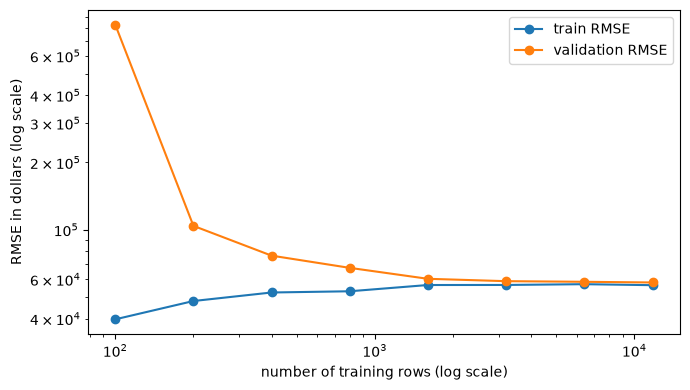

In [16]:
plt.figure(figsize=(7,4))
plt.plot(exp3.index, exp3["train_rmse"], marker="o", label="train RMSE")
plt.plot(exp3.index, exp3["val_rmse"], marker="o", label="validation RMSE")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("number of training rows (log scale)")
plt.ylabel("RMSE in dollars (log scale)")
plt.legend()
plt.tight_layout()
plt.show()

- At n=100, train RMSE is 39,712 and validation RMSE is 827,545. At n=11,805 they are 56,457 and 58,054. As the data increases, the gap between train RMSE and validation RSME decrease because more data helps to learn the pattern with complex model, so it can find the underlying pattern while less data with complex model leads to overfit.
- Training error goes up because the model shifts from memorising small data to showing an honest score on big data. With only 100 rows, the model can easily contort and bend to nearly every single point, yielding an overly optimistic error of 39,712 that is driven by memorisation. As you add thousands of rows, the model can no longer cheat by twisting itself to fit every individual quirk; instead, it is forced to find a stable average path, causing the training error to rise to its true, honest level of about 56,000 while validation error simultaneously falls to meet it.
- No. Another 10,000 rows would buy less than 1 percent. If we want a better model, we need better information (new columns) or a different kind of model.

In [21]:
Xs, ys = take(200)
ref = evaluate(make_model(1), Xs, ys)
print("reference, plain degree 1 on the same 200 rows: val RMSE",
      round(ref["val_rmse"]), "val R2", round(ref["val_r2"], 4))

rows = []
for a in [0.001, 0.1, 1, 10, 100, 1000, 10000, 100000]:
    r = evaluate(make_model(4, alpha=a), Xs, ys)
    r["alpha"] = a
    rows.append(r)
exp4 = pd.DataFrame(rows).set_index("alpha")
exp4["gap_rmse"] = exp4["val_rmse"] - exp4["train_rmse"]
print(exp4.round(3).to_string())

reference, plain degree 1 on the same 200 rows: val RMSE 66309 val R2 0.5469
            train_rmse    val_rmse  train_r2  val_r2    gap_rmse
alpha                                                           
0.001        47951.236  380290.240     0.784 -13.904  332339.005
0.100        52629.383   92961.095     0.740   0.109   40331.712
1.000        54664.749   68561.118     0.719   0.516   13896.369
10.000       56208.640   67002.423     0.703   0.537   10793.783
100.000      57576.281   67444.444     0.688   0.531    9868.164
1000.000     59218.502   67457.990     0.670   0.531    8239.488
10000.000    73133.215   73633.370     0.497   0.441     500.156
100000.000   96350.153   92489.740     0.127   0.118   -3860.413


- I would choose alpha = 10.0 because it achives the lowest validation rmse (67002.423) and R2 (0.537) while alpha 100.000, and 1000.000 is within 1% alpha 10.0, alpha 10.0 makes a simpler model. The values 10 to 1000 form a plateau where the differences are noise, avoiding too much regularization and give good penalty.
-  The reference plain degree-1 model has a validation RMSE of 66,309, as regularisation did not beat the simpler model. Regularization rescues a complex model that overfits, but it does not make it better than a simple model that was never overfitting. So with little data, start simple. Add complexity only when validation shows it helps, and regularize only when you see overfitting.It tells that adding complexity does not fix rather stay in a simpler model then add complex then regularized it.
- At alpha = 100,000 the validation RMSE (92,490) is lower than the train RMSE (96,350), which is why the gap is negative. But both are close to the baseline’s 98,548, and the R² values are only 0.127 on train and 0.118 on validation. The model learned almost nothing.

In [23]:
Xv500 = X_val.iloc[:500]
configs = {
    "degree 1": make_model(1),
    "degree 4 plain": make_model(4),
    "degree 4 ridge a=10": make_model(4, alpha=10) 
}
for name, mdl in configs.items():
    preds ,errs = [], []
    for seed in range(20):
        Xs, ys = take(200, seed)
        mdl.fit(Xs, ys)
        preds.append(mdl.predict(Xv500))
        errs.append(rmse(y_val, mdl.predict(X_val)))
    preds, errs = np.array(preds), np.array(errs)
    print(f"{name:22s} val RMSE median {np.median(errs):>11,.0f}  min {errs.min():>11,.0f}  "
          f"max {errs.max():>11,.0f} | median per-house pred std {np.median(preds.std(axis=0)):>8,.0f}")

degree 1               val RMSE median      65,805  min      64,452  max      66,459 | median per-house pred std   11,715
degree 4 plain         val RMSE median     753,495  min     293,836  max   1,476,188 | median per-house pred std   77,020
degree 4 ridge a=10    val RMSE median      69,866  min      64,432  max      76,694 | median per-house pred std   15,977


- 77,020 means for degree 4 and 11,715 for degree 1 tells that for the same house, the plain degree-4 model’s predicted price typically moves by about $77,020 depending on which 200 rows it trained on. Degree 1 moves by about $11,715. Degree 4 doesn’t “learn too much”. It has too many knobs for 200 rows, so it follows the quirks of whichever 200 rows it saw. I would choose degree 1 because it performs well on 200 rows and achieves lowest val RMSE.
- The Ridge (alpha=10) get crushed by high penalty (regularisation), which it achieves low std (15,977). The penalty shrinks the weights, so the curve is smoother and less sensitive to the sample. The std dropped from 77,020 to 15,977, about 5 times smaller. Ridge made degree 4 stable, but it still did not beat the simple model on 200 rows.
- Degree 1 is the most stable model here yet it is not the best model to choose because variance shrinks because there are more rows per knob. Now bias becomes the bigger problem, so the more complex model wins. it is high on bias which leads to underfit. 

In [27]:
cands = {"deg 1": make_model(1),
         "deg 2": make_model(2),
         "deg 3": make_model(3),
         "deg 4": make_model(4),
         "deg 5": make_model(5),
         "deg 5 Ridge": make_model(5, alpha=1000)}
rows = []
for name, mdl in cands.items():
    r = evaluate(mdl, X_tr, y_tr)
    r["model"] = name
    rows.append(r)
final = pd.DataFrame(rows).set_index("model")
final["gap_r2"] = final["train_r2"] - final["val_r2"]
final["pct_worse_than_best"] = (final["val_rmse"] / final["val_rmse"].min() - 1) * 100
print(final.round(4).to_string())
best = final["val_rmse"].idxmin()
print("lowest validation RMSE", best)

             train_rmse    val_rmse  train_r2  val_r2  gap_r2  pct_worse_than_best
model                                                                             
deg 1        63105.4994  64180.3220    0.5741  0.5755 -0.0014              10.5521
deg 2        59828.8292  61427.6711    0.6172  0.6111  0.0061               5.8106
deg 3        56456.5150  58054.3579    0.6591  0.6527  0.0065               0.0000
deg 4        55474.5650  58206.8026    0.6709  0.6508  0.0201               0.2626
deg 5        54950.1768  80548.0522    0.6771  0.3314  0.3457              38.7459
deg 5 Ridge  60954.7321  62275.5255    0.6027  0.6003  0.0023               7.2711
lowest validation RMSE deg 3


- Model deg = 3 won by the rule, eventhough gap r2 of deg 3 (0.0065) and 4 (0.0201).Degree 4’s gap is three times bigger. Deg 3 achieves the lowest validation rmse (58,054.3579). Model deg 4 is within 1& of model deg 3 by achieving validation rmse (58,206.8026) where it learns the noise. So I did choose the simpler model.
- Degree 5 with Ridge has a lower train score (0.6027) than degree 5 plain (0.6771) because degree 5 Ridge has been penalised harder which it leads to achieve lowest validation score (0.6003) but it does not mean it is the best model because it achieves the third highest validation rmse (60,954.7321) proves that it lears too many knobs and noise.
- The penalty stops the model degree 5 Ridge from memorising, so train R² falls (0.677 → 0.603). It is still better than the plain because validation R² jumps from 0.331 to 0.600, because it is stable on unseen houses. Tt scores 0.600 against 0.653 for plain degree 3. A heavily penalised degree 5 is a constrained, smoothed-out model, and it has no extra signal to exploit. The simpler degree 3 with no penalty does better.

In [31]:
winner = cands[best].fit(X_tr, y_tr)        # trained on the training rows only
plain = make_model(1).fit(X_tr, y_tr)

rows = [
    dict(model=best, test_rmse=rmse(y_test, winner.predict(X_test)), test_r2=r2_score(y_test, winner.predict(X_test))),
    dict(model="plain linear (deg1)", test_rmse=rmse(y_test, plain.predict(X_test)), test_r2=r2_score(y_test, plain.predict(X_test))),
    dict(model="baseline (average)", test_rmse=rmse(y_test, base.predict(X_test)), test_r2=r2_score(y_test, base.predict(X_test))),
]
print(pd.DataFrame(rows).set_index("model").round(4).to_string())
print("winner validation RMSE for comparison:", round(final.loc[best, "val_rmse"]))


                      test_rmse  test_r2
model                                   
deg 3                59372.1742   0.6465
plain linear (deg1)  65223.6511   0.5733
baseline (average)   99878.2445  -0.0005
winner validation RMSE for comparison: 58054


In [30]:
winner = cands[best].fit(X_tr, y_tr)        # trained on the training rows only
plain = make_model(1).fit(X_tr, y_tr)

rows = [
    dict(model=best, test_rmse=rmse(y_test, winner.predict(X_test)), test_r2=r2_score(y_test, winner.predict(X_test))),
    dict(model="plain linear (deg1)", test_rmse=rmse(y_test, plain.predict(X_test)), test_r2=r2_score(y_test, plain.predict(X_test))),
    dict(model="baseline (average)", test_rmse=rmse(y_test, base.predict(X_test)), test_r2=r2_score(y_test, base.predict(X_test))),
]
print(pd.DataFrame(rows).set_index("model").round(4).to_string())
print("winner validation RMSE for comparison:", round(final.loc[best, "val_rmse"]))


                      test_rmse  test_r2
model                                   
deg 3                59372.1742   0.6465
plain linear (deg1)  65223.6511   0.5733
baseline (average)   99878.2445  -0.0005
winner validation RMSE for comparison: 58054


- Validation RMSE of the winner is 58,054 and test RMSE is 59,372, it is not a problem. Test rmse is slightly higher than validation rmse because the validation test repeatedly test, tune and choose the winning model which it would have learned a minute noise which is harmless from train set. Validation was used to select the model, so its score is slightly optimistic; test is untouched, so it’s the honest estimate.
- The winning model (deg3) outperformed the plain linear model by reducing the test error by $5,851 and explaining R² rose from 0.573 to 0.647, 7.3 percentage points.
- Because if we do that, it leads to peeking at the test set, and making it completely destroying the test set's role as a completely unbiased. 

## Conclusion

- **What I tested:** I tested polynomial regression (degrees 1 to 5) and Ridge regularisation (alpha) on the California housing data. After removing 965 capped prices there were 19,675 rows. I split them into 11,805 train, 3,935 validation and 3,935 test rows, and I used 9 columns: median_income, housing_median_age, latitude, longitude and the ocean_proximity dummies. I compared models on validation RMSE and R², used the test set only once, and chose by this rule: lowest validation RMSE, and if two models are within 1%, pick the simpler one.

- **Little data (200 rows):** Degree 1 won (validation RMSE 66,309, R² 0.547). Complex models failed: degree 4 had train R² 0.891 but validation R² -201.8, about 14 times the baseline's error (1,402,922 vs 98,548). It had 714 features for 200 rows, so it memorised the quirks of those rows. That is overfitting (high variance).

- **Lots of data (11,805 rows):** Degree 3 won (validation RMSE 58,054, R² 0.653) against 64,180 and 0.575 for degree 1, about 9.5% lower error. The same degree-3 model that failed with 200 rows (about 0.9 rows per feature) works with 11,805 rows (about 54 rows per feature). Degree 4 was almost as good (R² 0.651), but degree 5 collapsed (validation R² 0.331 against train 0.677). Degree 1 was too simple (high bias, underfitting).

- **Learning curve (degree 3):** As rows grew from 100 to 11,805, the gap fell from about $788k to about $1.6k. Train error rose (39,712 to 56,457) because the model could no longer memorise, and validation error fell (827,545 to 58,054). They meet at about $58k, far below the baseline's 98,548, which is about what these 9 columns can reach. From 3,200 to 11,805 rows, validation error improved by only about 1.3%, so more rows would not help much. Better columns would.

- **Ridge:** On 200 rows, Ridge rescued degree 4 (alpha 10) from validation RMSE 1,402,922 to 67,002, about 21 times less error. But it did not beat the plain degree 1 model (66,309). Too strong a penalty underfits (alpha 100,000 gave validation R² 0.118). On the full data, Ridge lifted degree 5 from 0.331 to 0.600, still below plain degree 3 (0.653). So regularization rescues an overfit model, but it does not make it better than a simple model that was never overfitting.

- **Variance:** I trained each model on 20 different samples of 200 rows. For the same house, the plain degree-4 model's predicted price moved by a median of about $77,020 depending on the sample. Ridge degree 4 moved by $15,977, and degree 1 by $11,715. An unstable model cannot be trusted to quote a price.

- **Final model:** Degree 3 won on validation (degree 4 was within 0.3%, but degree 3 is simpler and had the lower RMSE). On the test set, scored once, it got RMSE 59,372 and R² 0.6465, against 65,224 and 0.5733 for plain linear and 99,878 for the baseline. That is about 9% lower error ($5,851) and R² up by about 0.07. Test RMSE was 2.3% above validation, which is small, because validation was used to choose the model and so its score was slightly optimistic.

- **Caveats:** The small-data results (Ridge and variance) come from one random 200-row sample. Validation is a single split, so every number is an estimate (cross-validation on Day 12 will average over many splits). The model uses only 9 columns, and latitude, longitude and the ocean columns overlap, so single coefficients should be read with caution.

- **How much complexity can my data afford?** With 200 rows, only a straight line. With about 11,800 rows, a degree-3 curve (around 54 rows per feature). Degree 4 is the limit, and degree 5 is too much even with a penalty.